In [52]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib import rcParams
rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "Heiti TC", "Arial", 'Times New Roman'] # 中文字体优先，解决中文显示问题
rcParams["axes.unicode_minus"] = False  # 解决负号显示问题（原有，保留


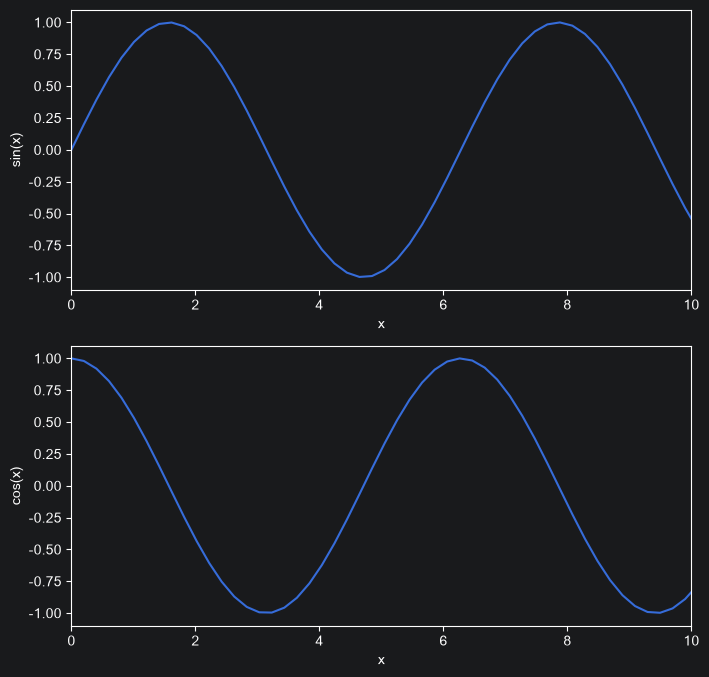

In [53]:
# 全程都在plt 接口  状态接口
x = np.linspace(0, 20, 100)
y1 = np.sin(x)
y2 = np.cos(x)
# 创建画布
plt.figure(figsize=(8, 8))
# 创建两行一列的子图
ax1 = plt.subplot(2, 1, 1) # 第一个子图
ax1.plot(x, y1)
plt.xlim(0, 10) # 设置 x 轴范围 默认 自动
plt.xlabel('x')
plt.ylabel('sin(x)')

ax2 = plt.subplot(2, 1, 2) # 第二个子图
plt.xlim(0, 10) # 设置 x 轴范围 默认是
ax2.set_xlabel('x')
ax2.set_ylabel('cos(x)')


ax2.plot(x, y2)
plt.show()

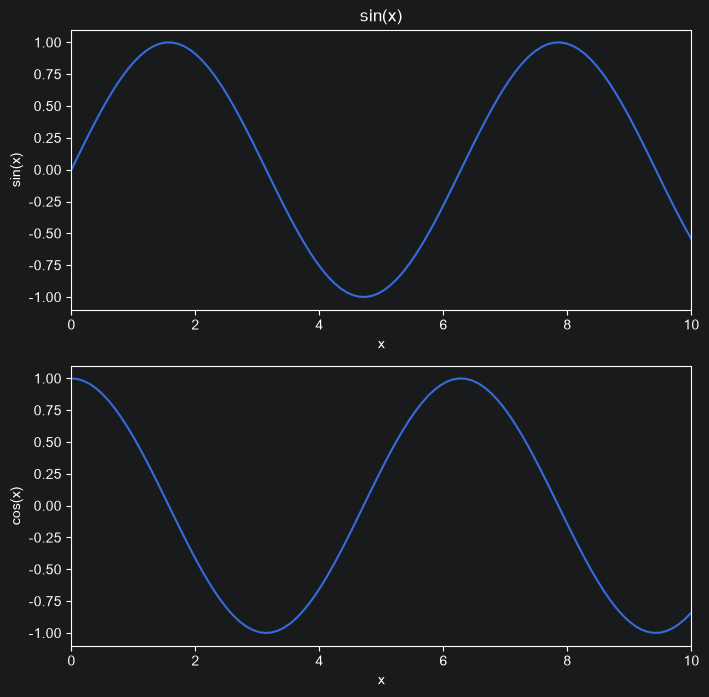

In [54]:
# 面向对象接口
x = np.linspace(0, 10, 100)
y1 = np.sin(x)
y2 = np.cos(x)
fig, ax = plt.subplots(2, 1, figsize=(8, 8))
ax[0].plot(x, y1)
ax[0].set_xlim(0, 10)
ax[0].set_xlabel('x')
ax[0].set_ylabel('sin(x)')
ax[0].set_title('sin(x)')

ax[1].plot(x, y2)
ax[1].set_xlim(0, 10)
ax[1].set_xlabel('x')
ax[1].set_ylabel('cos(x)')
plt.show()





In [55]:
# 单变量可视化
from pathlib import Path
import pandas as pd

source_path  = Path.cwd().parent / "资料-pd"

df = pd.read_csv(source_path / "weather.csv")

In [56]:
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   str    
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   str    
dtypes: float64(4), str(2)
memory usage: 68.6 KB


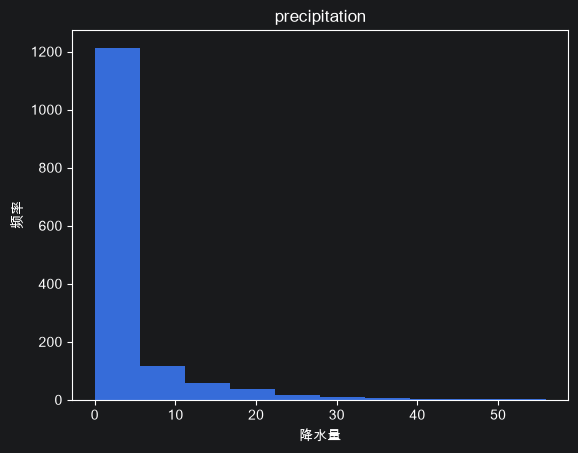

In [58]:
# 直方图
plt.figure()
plt.hist(df['precipitation'],bins=10)
plt.title('precipitation')
plt.xlabel("降水量")
plt.ylabel('频率') # 频率

plt.show()



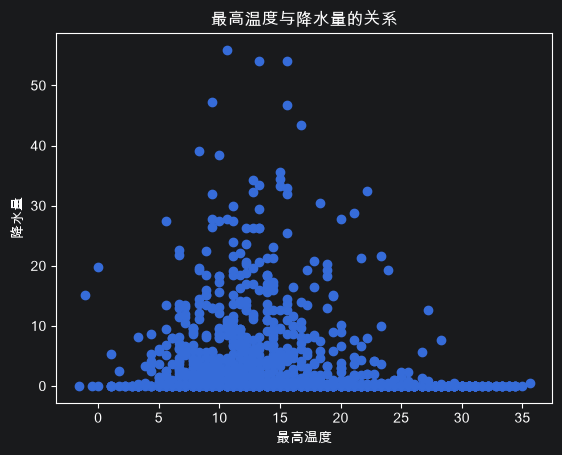

In [59]:
# 多变量可视化
# 散点图
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
# scatter
ax.scatter(df['temp_max'], df['precipitation'])
ax.set_xlabel("最高温度")
ax.set_ylabel("降水量")
ax.set_title("最高温度与降水量的关系")
plt.show()






In [64]:
# 多变量 散点图 + 颜色（）
def year_color(data):
    year = pd.to_datetime(data).year
    match year:
        case 2012:
            color = "r"
        case 2013:
            color = "b"
        case 2014:
            color = "g"
        case _:
            color = "k"
    return color

df["color"] = df["date"].apply(year_color)
df.head()


,date,precipitation,temp_max,temp_min,wind,weather,color
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,r
1,2012-01-02,10.9,10.6,2.8,4.5,rain,r
2,2012-01-03,0.8,11.7,7.2,2.3,rain,r
3,2012-01-04,20.3,12.2,5.6,4.7,rain,r
4,2012-01-05,1.3,8.9,2.8,6.1,rain,r


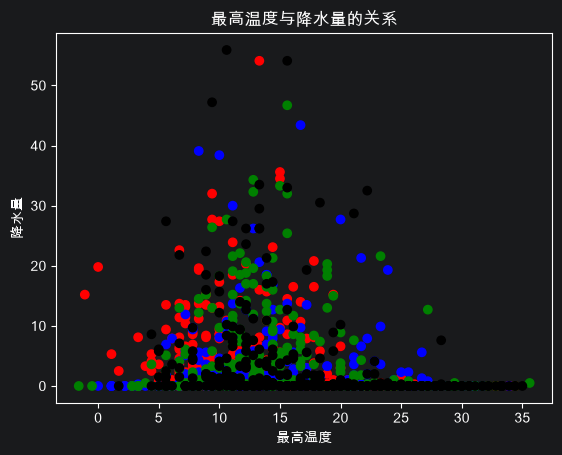

In [65]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.scatter(df['temp_max'], df['precipitation'], c=df['color'])
ax.set_xlabel("最高温度")
ax.set_ylabel("降水量")
ax.set_title("最高温度与降水量的关系")
plt.show()




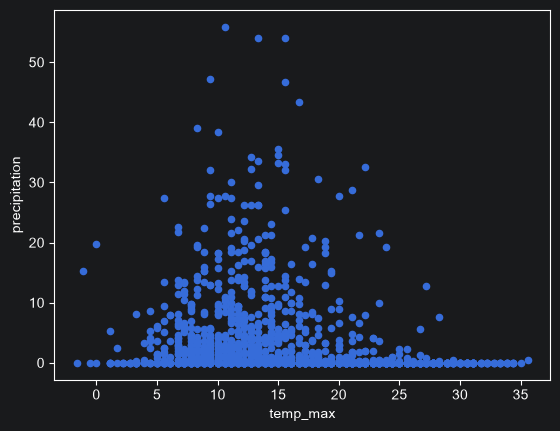

In [66]:
# pandas可视化   pandas提供了非常方便的绘图功能，可以直接在DataFrame或Series上调用plot()方法来生成各种类型的图表。
df.plot.scatter(x='temp_max', y='precipitation')
plt.show()


In [67]:
df = pd.read_csv(source_path / "sleep.csv")
df.head()


,person_id,gender,age,occupation,sleep_duration,sleep_quality,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
0,1,Male,29,Manual Labor,7.4,7.0,41,7,Obese,124/70,91,8539,NaN
1,2,Female,43,Retired,4.2,4.9,41,5,Obese,131/86,81,18754,NaN
2,3,Male,44,Retired,6.1,6.0,107,4,Underweight,122/70,81,2857,NaN
3,4,Male,29,Office Worker,8.3,10.0,20,10,Obese,124/72,55,6886,NaN
4,5,Male,67,Retired,9.1,9.5,19,4,Overweight,133/78,97,14945,Insomnia


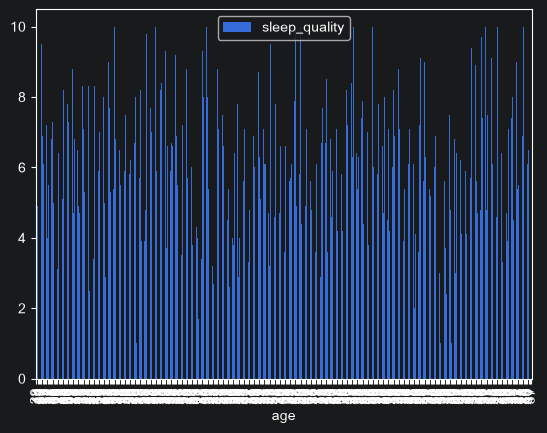

In [70]:
 # 柱状图
df.plot.bar(x='age', y='sleep_quality')
plt.show()



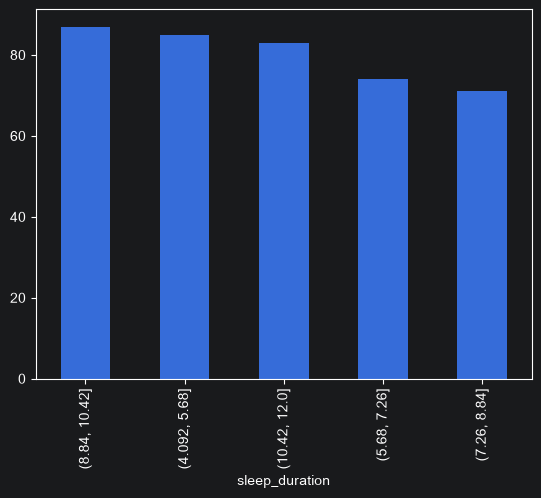

In [71]:
pd.cut(df["sleep_duration"], bins=5).value_counts().plot.bar()
plt.show()


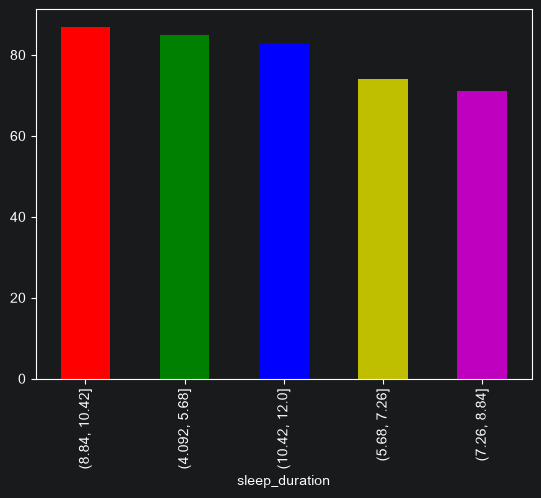

In [73]:
# 设置颜色
pd.cut(df["sleep_duration"], bins=5).value_counts().plot.bar(color=['r', 'g', 'b', 'y', 'm'])
plt.show()


<Axes: xlabel='sleep_duration'>

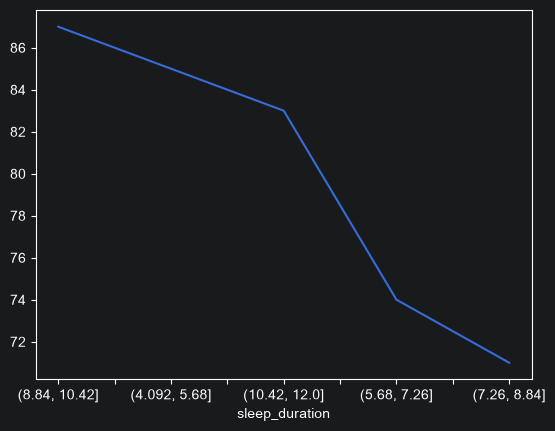

In [74]:
# 折线图
pd.cut(df["sleep_duration"], bins=5).value_counts().plot()

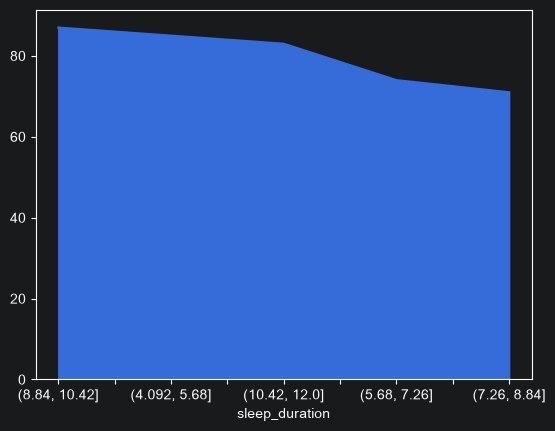

In [75]:
# 面积图
pd.cut(df["sleep_duration"], bins=5).value_counts().plot.area()
plt.show()


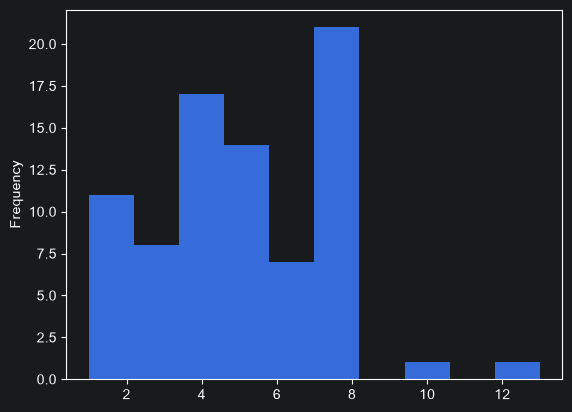

In [77]:
# 直方图
df['sleep_duration'].value_counts().plot.hist()
plt.show()


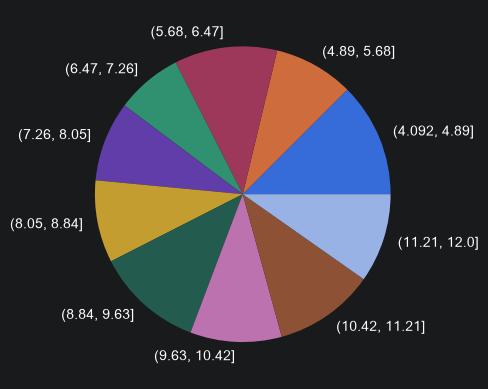

In [81]:
#饼形图
pd.cut(df['sleep_duration'], bins=10).value_counts().sort_index().plot.pie()
plt.show()



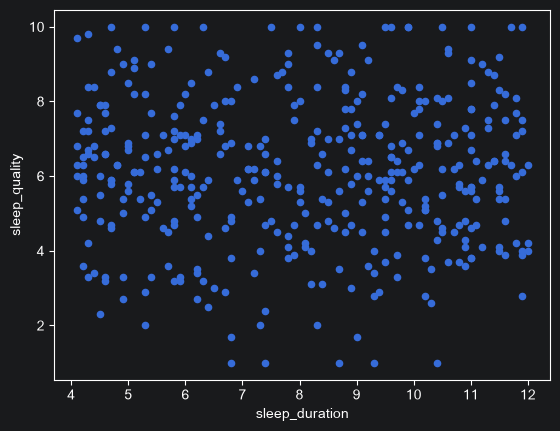

In [82]:
# 双变量可视化     展示两组数据之间的关系 能够揭示两个变量之间的相关性
df.plot.scatter(x='sleep_duration', y='sleep_quality')
plt.show()


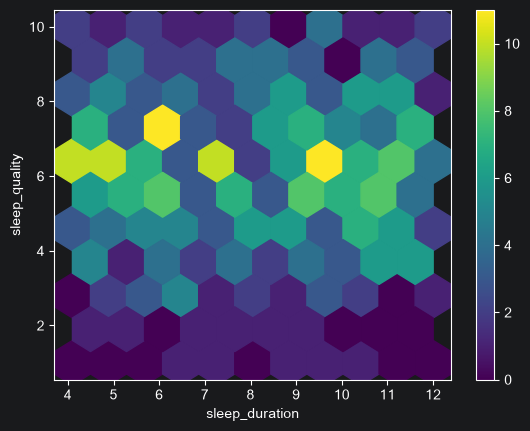

In [84]:
#蜂窝图
df.plot.hexbin(x='sleep_duration', y='sleep_quality', gridsize=10)
plt.show()


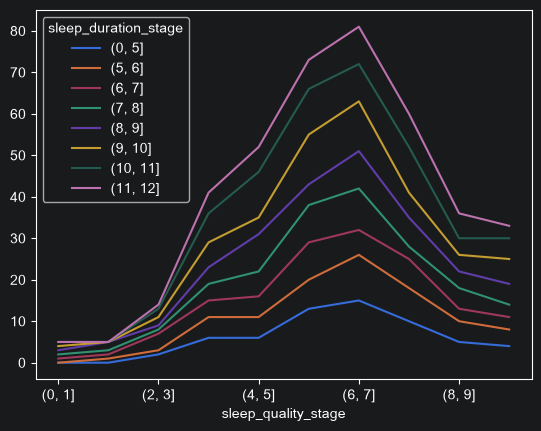

In [92]:
#堆叠图 是在透视表的基础上绘制的
df["sleep_quality_stage"] = pd.cut(df["sleep_quality"], range(11))
df["sleep_duration_stage"] = pd.cut(df["sleep_duration"], [0, 5, 6, 7, 8, 9, 10, 11, 12])
#df.pivot_table(index='sleep_quality_stage', columns='sleep_duration_stage', values='person_id', aggfunc='count').plot.bar()
df.pivot_table(index='sleep_quality_stage', columns='sleep_duration_stage', values='person_id', aggfunc='count').plot.line(stacked=True)

plt.show()
